In [8]:
import pandas as pd
import numpy as np

# 1. HEDEF (TARGET) DOĞRULAMA
target_col = 'Bactérias coliformes'

print("=== 1. HEDEF DEĞİŞKEN (TARGET) ANALİZİ ===")
print("Hedef Sütun:", target_col)
print("Pozitif Sınıf (1): Uygunsuzluk var (Mevzuata aykırı)")
print("Negatif Sınıf (0): Uygunsuzluk yok (Temiz su)\n")

counts = df_features[target_col].value_counts(dropna=False)
percents = df_features[target_col].value_counts(normalize=True, dropna=False) * 100
target_summary = pd.DataFrame({'Adet': counts, 'Yüzde (%)': percents.round(2)})
display(target_summary)


# 2. ÖZELLİKLERİ (FEATURES) 6 GRUBA AYIRMA
# A. Kimlik ve Bölge Bilgileri (Modele GİRMEYECEK - Sadece Gruplama ve Takip İçin)
id_group = ['FREGUESIA', 'ZAPE NOME', 'DATA AMOSTRAGEM']

# B. Hedef Değişken (Modele GİRMEYECEK - Tahmin Edilecek Şey)
target_group = [target_col]

# C. Yüksek Oranda Boş Olanlar (%80 üstü eksik - Modele girmesi anlamsız olanlar)
missing_ratios = (df_features.isna().sum() / len(df_features)) * 100
too_empty_group = missing_ratios[missing_ratios > 80].index.tolist() # ekisk veri oranı %80 in üzerinde olanları listeledi

# D. Kalan Kullanılabilir Sütunlar
usable_cols = [c for c in df_features.columns if c not in id_group and c not in target_group and c not in too_empty_group]

# Bu sütunları mantıksal alt gruplara ayıralım:
# - Meteoroloji (Sıcaklık, Yağış, Nem)
meteo_group = [c for c in usable_cols if any(k in c.upper() for k in ['TEMP', 'PREC', 'CHUVA', 'UMID', 'VENTO', 'SOLAR', 'RAD'])]

# - Takvim (Ay, Yıl, Mevsim, Sin/Cos kodlamaları)
calendar_group = [c for c in usable_cols if any(k in c.upper() for k in ['MES', 'ANO', 'ESTACAO', 'VERAO', 'SIN', 'COS', 'DAY', 'MONTH'])]

# - Geçmiş / Hafıza / Kinetik Özellikler (Lag, Moving Average, Diff, Média móvel)
history_kinetic_group = [c for c in usable_cols if any(k in c.upper() for k in ['LAG', 'ROLL', 'DIFF', 'MEDIA', 'HIST', 'PAST', 'TAXA'])]

# - Fizikokimyasal Saha Ölçümleri (Klor, Bulanıklık, pH vb.)
chem_group = [c for c in usable_cols if c not in meteo_group and c not in calendar_group and c not in history_kinetic_group]

print("\n=== 2. ÖZELLİK (FEATURE) GRUPLARI ===")
print(f"Kimlik ve İdari Sütunlar (Grup A)         : {len(id_group)} adet -> {id_group}")
print(f"Hedef Sütun (Grup B)                      : {len(target_group)} adet -> {target_group}")
print(f"Aşırı Eksik/Elenecekler (Grup C)          : {len(too_empty_group)} adet")
print(f"Fizikokimyasal Ölçümler (Grup D)          : {len(chem_group)} adet -> {chem_group[:5]}...")
print(f"Meteorolojik Özellikler (Grup E)          : {len(meteo_group)} adet -> {meteo_group[:5]}...")
print(f"Takvim/Mevsim Özellikleri (Grup F)        : {len(calendar_group)} adet -> {calendar_group}")
print(f"Geçmiş/Hafıza/Kinetik Özellikler (Grup G) : {len(history_kinetic_group)} adet -> {history_kinetic_group[:5]}...")
print(f"\nModele Girebilecek Toplam Temiz Özellik   : {len(usable_cols)} adet")

=== 1. HEDEF DEĞİŞKEN (TARGET) ANALİZİ ===
Hedef Sütun: Bactérias coliformes
Pozitif Sınıf (1): Uygunsuzluk var (Mevzuata aykırı)
Negatif Sınıf (0): Uygunsuzluk yok (Temiz su)



NameError: name 'df_features' is not defined

In [ ]:
import pandas as pd

# 1. Asıl modelleme tablosunu okuyalım
csv_path = "../data/raw/01_Data/Base_Tech4Aqua_Features_Avancadas.csv"
df_features = pd.read_csv(csv_path)

print("=== VERİ BOYUTU ===")
print("Satır ve Sütun Sayısı:", df_features.shape)

print("\n=== TÜM SÜTUNLAR ===")
for i, col in enumerate(df_features.columns):
    print(f"{i+1}. {col}")

print("\n=== İLK 3 SATIR ===")
display(df_features.head(3))

=== VERİ BOYUTU ===
Satır ve Sütun Sayısı: (1540, 113)

=== TÜM SÜTUNLAR ===
1. FREGUESIA
2. ZAPE NOME
3. DATA AMOSTRAGEM
4. 1,2 – dicloroetano
5. Acrilamida
6. Alacloro
7. Alfa total
8. Alumínio
9. Amónio
10. Antimónio
11. Arsénio
12. Bactérias coliformes
13. Benzeno
14. Benzo(a)pireno
15. Benzo(b)fluoranteno
16. Benzo(ghi) perileno
17. Benzo(k)fluoranteno
18. Beta total
19. Boro
20. Bromatos
21. Bromodiclorometano
22. Bromofórmio
23. Cheiro a 25ºC
24. Chumbo
25. Cianetos
26. Cloratos
27. Cloretos
28. Cloritos
29. Cloro livre
30. Clorofórmio
31. Clortolurão
32. Clostridium perfringens
33. Cobre
34. Condutividade
35. Cor
36. Cryptosporidium
37. Crómio
38. Cádmio
39. Cálcio
40. Cálculo da DI (Somatório Diretiva 2013/51/EURATOM)
41. Desinfetante residual
42. Dibromoclorometano
43. Dimetoato
44. Dose indicativa
45. Dureza total
46. EPTC
47. Enterococos
48. Escherichia coli (E. coli)
49. Ferro
50. Fluoretos
51. Giardia
52. Indeno(1,2,3-cd)pireno
53. Isoproturão
54. Linurão
55. MCPA
56. Mag

,FREGUESIA,ZAPE NOME,DATA AMOSTRAGEM,"1,2 – dicloroetano",Acrilamida,Alacloro,Alfa total,Alumínio,Amónio,Antimónio,...,FLAG_CALOR_EXTREMO,FLAG_RUNOFF_RISCO,INDICE_ESTRESSE_CONJUNTO,INDICE_RUNOFF_TURVACAO,DEMANDA_CLORO_PROXY,DEGRADACAO_TERMICA_CLORO,MES,SIN_MES,COS_MES,FLAG_VERAO
0,BOTICAS,BOTICAS/EIRÓ R42,2014-02-07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,1.0,0.0,0.0,NaN,33.500000,2,8.660254e-01,0.5,0.0
1,BOTICAS,BOTICAS/EIRÓ R42,2014-04-07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,NaN,84.000000,4,8.660254e-01,-0.5,0.0
2,BOTICAS,BOTICAS/EIRÓ R42,2014-06-06,NaN,NaN,NaN,NaN,NaN,0.1,NaN,...,0.0,1.0,0.0,0.0,2.0,65.333333,6,1.224647e-16,-1.0,1.0


In [ ]:
import pandas as pd

# 1. Veri sözlüğünü okuyup sütun açıklamalarına göz atalım
dict_path = "../data/raw/01_Data/Data_Dictionary.csv"
try:
    df_dict = pd.read_csv(dict_path)
    print("=== VERİ SÖZLÜĞÜ (İLK 15 SATIR) ===")
    display(df_dict.head(15))
except Exception as e:
    print("Veri sözlüğü okunamadı:", e)

# 2. Eksik değer oranı en yüksek olan ilk 15 sütun
print("\n=== EN ÇOK EKSİK DEĞERİ OLAN SÜTUNLAR ===")
missing_ratio = (df_features.isna().sum() / len(df_features)) * 100
print(missing_ratio.sort_values(ascending=False).head(15))

# 3. Mükerrer (birebir kopya) satır var mı?
print("\n=== TEKRAR EDEN (DUPLICATE) SATIR SAYISI ===")
print(df_features.duplicated().sum())

=== VERİ SÖZLÜĞÜ (İLK 15 SATIR) ===


,Feature_Name,Category,Description,Measurement_Unit,Statutory_Standard_or_Baseline,Data_Type,Non_Null_Count
0,FREGUESIA,Physicochemical / Trace Chemistry,Measured chemical or physical water quality pa...,mg/L or µg/L,Statutory drinking water limit,str,1540
1,ZAPE NOME,Physicochemical / Trace Chemistry,Measured chemical or physical water quality pa...,mg/L or µg/L,Statutory drinking water limit,str,1540
2,DATA AMOSTRAGEM,Physicochemical / Trace Chemistry,Measured chemical or physical water quality pa...,mg/L or µg/L,Statutory drinking water limit,str,1540
3,"1,2 – dicloroetano",Physicochemical Disinfection,Free residual chlorine disinfectant concentration,mg/L Cl2,>= 0.20 mg/L minimum statutory recommendation,float64,59
4,Acrilamida,Physicochemical / Trace Chemistry,Measured chemical or physical water quality pa...,mg/L or µg/L,Statutory drinking water limit,float64,1
5,Alacloro,Physicochemical Disinfection,Free residual chlorine disinfectant concentration,mg/L Cl2,>= 0.20 mg/L minimum statutory recommendation,float64,38
6,Alfa total,Physicochemical / Trace Chemistry,Measured chemical or physical water quality pa...,mg/L or µg/L,Statutory drinking water limit,float64,49
7,Alumínio,Physicochemical / Trace Chemistry,Measured chemical or physical water quality pa...,mg/L or µg/L,Statutory drinking water limit,float64,83
8,Amónio,Physicochemical / Trace Chemistry,Measured chemical or physical water quality pa...,mg/L or µg/L,Statutory drinking water limit,float64,106
9,Antimónio,Physicochemical / Trace Chemistry,Measured chemical or physical water quality pa...,mg/L or µg/L,Statutory drinking water limit,float64,59



=== EN ÇOK EKSİK DEĞERİ OLAN SÜTUNLAR ===
Giardia                                               99.935065
Acrilamida                                            99.935065
Cryptosporidium                                       99.935065
Dimetoato                                             99.805195
EPTC                                                  99.805195
Potássio                                              99.740260
Cálculo da DI (Somatório Diretiva 2013/51/EURATOM)    99.675325
Cloritos                                              99.610390
Cloratos                                              99.480519
Beta total                                            98.896104
Linurão                                               98.506494
Isoproturão                                           98.441558
Clortolurão                                           98.441558
MCPA                                                  98.246753
Cloro livre                                           98.1818

In [ ]:
import pandas as pd
import os

data_path = "../data/raw/01_Data"
files = os.listdir(data_path)
print("Veri dosyaları:", files)

# İlk csv veya excel dosyasını otomatik bulup okuyalım
target_file = [f for f in files if f.endswith(('.csv', '.xlsx'))][0]
file_full_path = os.path.join(data_path, target_file)

if target_file.endswith('.csv'):
    df = pd.read_csv(file_full_path)
else:
    df = pd.read_excel(file_full_path)

print(f"\nOkunan dosya: {target_file}")
print("Boyut (Satır, Sütun):", df.shape)
print("\nİlk 5 satır:")
display(df.head())

Veri dosyaları: ['Base_Revisada_Tech4Aqua.xlsx', 'Base_Tech4Aqua_Features_Avancadas.csv', 'Base_Tech4Aqua_Features_Avancadas.xlsx', 'Data_Dictionary.csv']

Okunan dosya: Base_Revisada_Tech4Aqua.xlsx
Boyut (Satır, Sütun): (7887, 20)

İlk 5 satır:


,FREGUESIA,ZAPE NOME,ZAPE CODE,ZAPE EGCODE,ZAPE VOLUME,ZAPE POPULACAO,PA CODE,PA NOME,LAB NOME,CODIGO ANALISE,CONTROL TYPE ANALISE,DATA AMOSTRAGEM,PARAMETRO NOME,OPERADOR,RESULTADO,UNIDADES,FICHEIRO FONTE,TEMP MÁX (ºC),PRECIPITAÇÃO (mm),UMIDADE MÉDIA (%)
0,BOTICAS,BOTICAS/EIRÓ R42,PT3827,R42,-,-,-,-,-,-,CR2,2016-02-12 00:00:00,Escherichia coli (E. coli),=,0,Número/100 mL,IDQA 2016 - CMBoticas.xlsx,11.9,20.6,98.2
1,BOTICAS,BOTICAS/EIRÓ R42,PT3827,R42,-,-,-,-,-,-,CR2,2016-02-12 00:00:00,Bactérias coliformes,=,0,N/100 mL,IDQA 2016 - CMBoticas.xlsx,11.9,20.6,98.2
2,BOTICAS,BOTICAS/EIRÓ R42,PT3827,R42,-,-,-,-,-,-,CR2,2016-02-12 00:00:00,Desinfetante residual,=,0.1,mg/L,IDQA 2016 - CMBoticas.xlsx,11.9,20.6,98.2
3,BOTICAS,BOTICAS/EIRÓ R42,PT3827,R42,-,-,-,-,-,-,CR2,2016-02-12 00:00:00,Cheiro a 25ºC,<,1,Fator de diluição,IDQA 2016 - CMBoticas.xlsx,11.9,20.6,98.2
4,BOTICAS,BOTICAS/EIRÓ R42,PT3827,R42,-,-,-,-,-,-,CR2,2016-02-12 00:00:00,Sabor a 25ºC,<,1,Fator de diluição,IDQA 2016 - CMBoticas.xlsx,11.9,20.6,98.2


1. MODELLEME VERİ SETİ BOYUTU
Hedefi dolu (etiketli) gerçek gözlem sayısı: 522

2. HEDEF SINIF DAĞILIMI (TEMİZ VS RİSKLİ)


,Durum,Adet,Yüzde (%)
0,0 (Temiz / Uygun),438,83.91
1,1 (Uygunsuz / Bakterili),84,16.09



3. BÖLGE (ZAPE) BAZINDA DAĞILIM
Etiketli verideki toplam farklı ZAPE sayısı: 72

İlk 10 ZAPE için dağılım:


,Temiz (0),Uygunsuz (1)
ZAPE NOME,,
BOTICAS/EIRÓ R42,66,0
Cabril+Cavalos,4,8
Cabril+Cavalos+Chãos,83,7
Castelões - Vale da Castanheira/Vale da Ortiga,1,0
Chaves,8,2
Selhariz - Vale da Touça/Capela,1,2
Sistema Novo do Couto,2,1
Sistema Principal da Agrela,1,0
Sistema Secundário da Agrela,1,0



Hiç mikrobiyolojik uygunsuzluk (1) görülmeyen ZAPE sayısı: 31

4. KEŞİF GRAFİKLERİ


/var/folders/wx/2wsk45h93v1fm0btjb1t741h0000gn/T/ipykernel_96316/2306846485.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=['Temiz (0)', 'Uygunsuz (1)'], y=[class_counts.get(0, 0), class_counts.get(1, 0)], ax=axes[0], palette=['#4CAF50', '#F44336'])


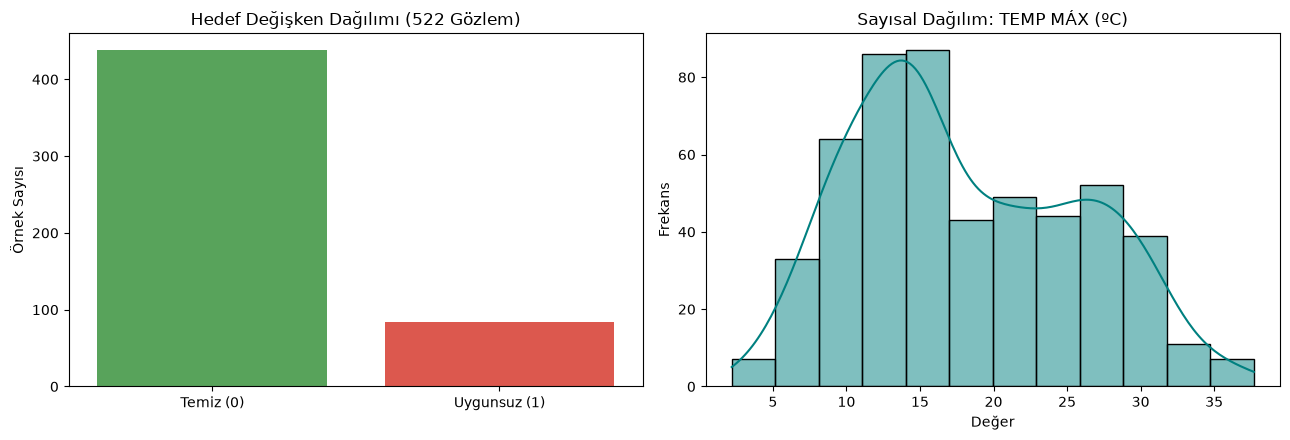

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. HEDEFİ İKİLİ (0 / 1) YAPMA VE SADECE ETİKETLİ 522 SATIRI ALMA
# Bakteri sayısı > 0 ise 1 (Riskli), == 0 ise 0 (Temiz)
target_raw = 'Bactérias coliformes'

# Yalnızca hedef ölçümü olan (NaN olmayan) satırları alıyoruz (Tam 522 satır olmalı)
df_clean = df_features[df_features[target_raw].notna()].copy()
df_clean['TARGET_BINARY'] = (df_clean[target_raw] > 0).astype(int)

print("==================================================")
print("1. MODELLEME VERİ SETİ BOYUTU")
print("==================================================")
print(f"Hedefi dolu (etiketli) gerçek gözlem sayısı: {len(df_clean)}")

print("\n==================================================")
print("2. HEDEF SINIF DAĞILIMI (TEMİZ VS RİSKLİ)")
print("==================================================")
class_counts = df_clean['TARGET_BINARY'].value_counts()
class_percents = df_clean['TARGET_BINARY'].value_counts(normalize=True) * 100
summary_df = pd.DataFrame({
    'Durum': ['0 (Temiz / Uygun)', '1 (Uygunsuz / Bakterili)'],
    'Adet': [class_counts.get(0, 0), class_counts.get(1, 0)],
    'Yüzde (%)': [class_percents.get(0, 0).round(2), class_percents.get(1, 0).round(2)]
})
display(summary_df)

print("\n==================================================")
print("3. BÖLGE (ZAPE) BAZINDA DAĞILIM")
print("==================================================")
zape_col = 'ZAPE NOME'
print(f"Etiketli verideki toplam farklı ZAPE sayısı: {df_clean[zape_col].nunique()}")

# ZAPE bazında çapraz tablo (Temiz / Uygunsuz)
zape_summary = pd.crosstab(df_clean[zape_col], df_clean['TARGET_BINARY'])
zape_summary.columns = ['Temiz (0)', 'Uygunsuz (1)']
print("\nİlk 10 ZAPE için dağılım:")
display(zape_summary.head(10))

# Hiç uygunsuzluk görülmeyen bölge sayısı
sifir_uygunsuzluk = (zape_summary['Uygunsuz (1)'] == 0).sum()
print(f"\nHiç mikrobiyolojik uygunsuzluk (1) görülmeyen ZAPE sayısı: {sifir_uygunsuzluk}")

print("\n==================================================")
print("4. KEŞİF GRAFİKLERİ")
print("==================================================")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Sol Grafik: Sınıf Dağılımı
sns.barplot(x=['Temiz (0)', 'Uygunsuz (1)'], y=[class_counts.get(0, 0), class_counts.get(1, 0)], ax=axes[0], palette=['#4CAF50', '#F44336'])
axes[0].set_title("Hedef Değişken Dağılımı (522 Gözlem)")
axes[0].set_ylabel("Örnek Sayısı")

# Sağ Grafik: Sıcaklık Dağılımı (varsa TEMP MÁX)
temp_cols = [c for c in df_clean.columns if 'TEMP' in c.upper()]
if temp_cols:
    chosen_col = temp_cols[0]
    sns.histplot(df_clean[chosen_col].dropna(), kde=True, ax=axes[1], color='teal')
    axes[1].set_title(f"Sayısal Dağılım: {chosen_col}")
    axes[1].set_xlabel("Değer")
    axes[1].set_ylabel("Frekans")

plt.tight_layout()
plt.show()

5. GÜN: KEŞİFSEL VERİ ANALİZİ (EDA) EKSİKSİZ KONTROL RAPORU

>>> 1. EKSİK DEĞERLER TABLOSU (En Çok Boş Olan İlk 15 Sütun)


,Eksik Adet,Eksik Yüzde (%)
Cálculo da DI (Somatório Diretiva 2013/51/EURATOM),522,100.00
Cryptosporidium,522,100.00
Acrilamida,522,100.00
Giardia,522,100.00
Rádio 226,520,99.62
Polónio 210,520,99.62
Urânio 238,520,99.62
Urânio 234,520,99.62
Dimetoato,519,99.43
EPTC,519,99.43



>>> 2. YİNELENEN (KOPYA) SATIR SAYISI
Birebir tekrar eden satır sayısı: 0
Değerlendirme: Veri setinde mükerrer satır yok, gözlemler bağımsız numuneleri temsil ediyor.

>>> 3. HEDEF SINIF DAĞILIMI


,Sınıf,Adet,Oran (%)
0,0 (Temiz / Uygun),438,83.91
1,1 (Uygunsuz / Bakterili),84,16.09



>>> 4 & 5. BÖLGE (ZAPE) BAŞINA GÖZLEM VE POZİTİF/NEGATİF SAYILARI (İlk 15 Bölge)


,Temiz (0),Uygunsuz (1),Toplam Numune
ZAPE NOME,,,
Toplam,438,84,522
Sistema de Seara Velha,97,6,103
Cabril+Cavalos+Chãos,83,7,90
Sistema de France/ Moreiras,63,3,66
BOTICAS/EIRÓ R42,66,0,66
Sistema de France,29,1,30
Sistema de Moreiras,24,0,24
Cabril+Cavalos,4,8,12
Chaves,8,2,10



>>> 6. SAYISAL ÖZELLİKLERİN ÖZET İSTATİSTİKLERİ (Örnek İlk 8 Sayısal Değişken)


,"1,2 – dicloroetano",Acrilamida,Alacloro,Alfa total,Alumínio,Amónio,Antimónio,Arsénio
count,59.00,0.0,38.00,37.00,59.00,106.00,59.00,79.00
mean,0.52,NaN,0.04,0.06,34.01,0.06,1.97,7.11
std,0.28,NaN,0.02,0.04,23.01,0.03,1.29,4.70
min,0.10,NaN,0.01,0.04,10.00,0.02,1.00,1.00
25%,0.30,NaN,0.03,0.04,16.50,0.05,1.00,3.55
50%,0.50,NaN,0.05,0.04,30.00,0.05,1.00,7.00
75%,0.75,NaN,0.05,0.05,44.50,0.10,3.50,10.00
max,1.00,NaN,0.05,0.27,123.00,0.10,4.00,34.00



>>> 7. ÜÇ TEMEL GRAFİK OLUŞTURULUYOR...


/var/folders/wx/2wsk45h93v1fm0btjb1t741h0000gn/T/ipykernel_96316/4180740870.py:56: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=class_dist['Sınıf'], y=class_dist['Adet'], palette=['#2ecc71', '#e74c3c'], ax=ax1)


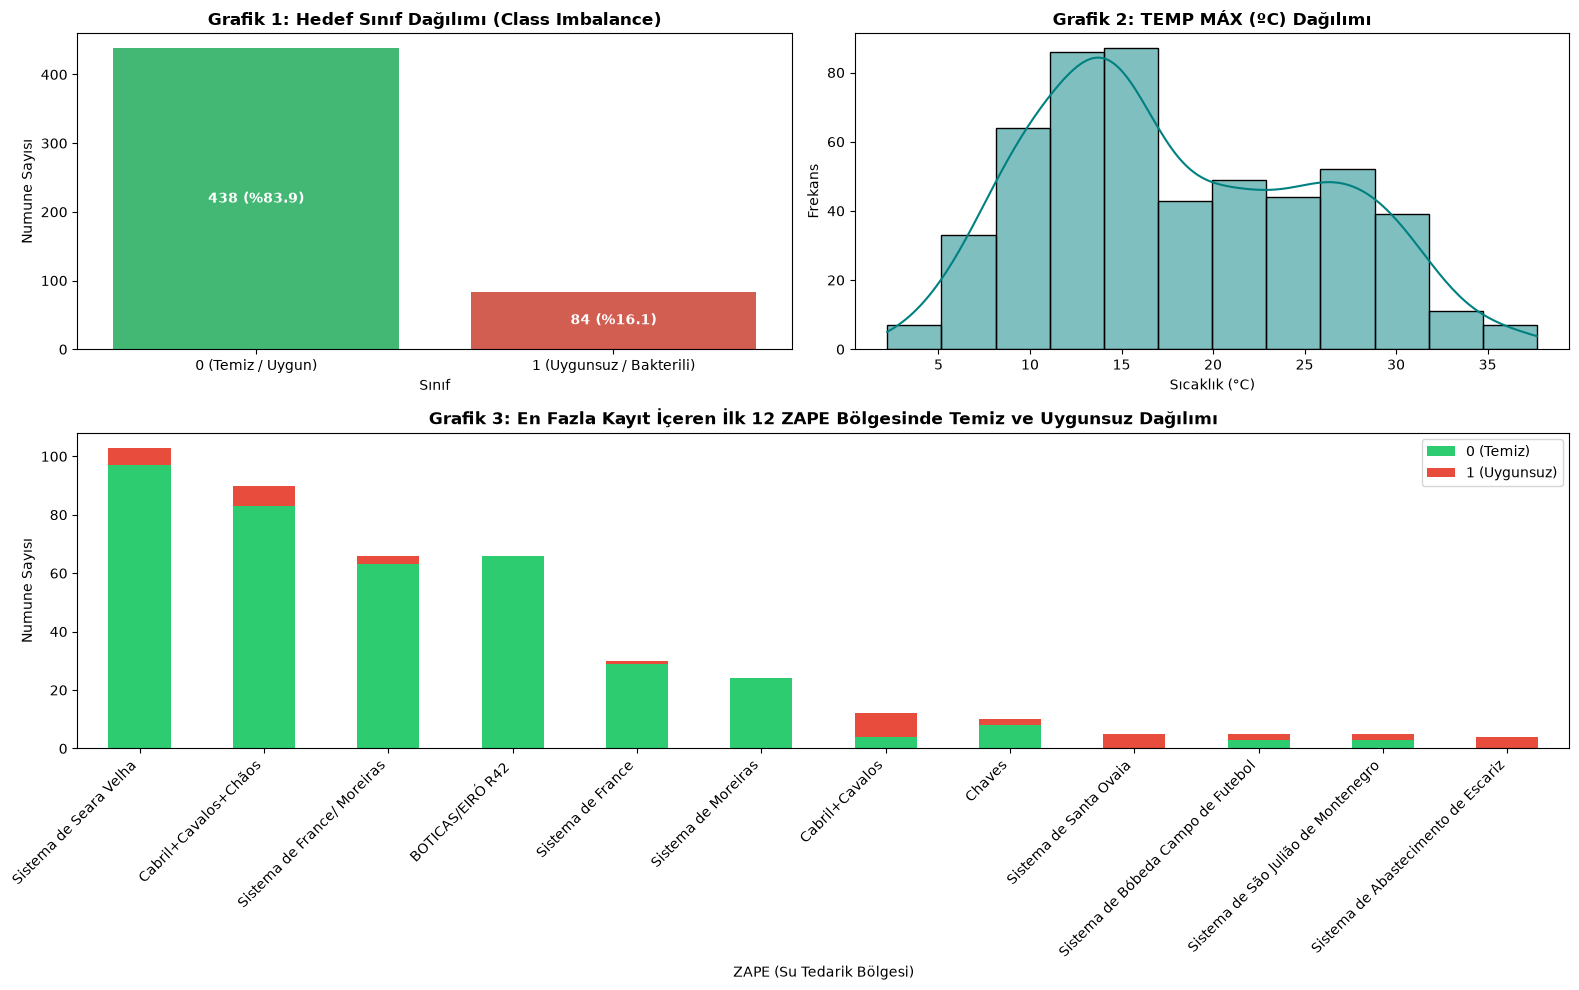


>>> 8. VERİYLE İLGİLİ FARK EDİLEN SORUNLARIN KISA LİSTESİ:
1. Şiddetli Sınıf Dengesizliği: Pozitif sınıf yalnızca %16.09 (Accuracy metriği yanıltıcı olacaktır).
2. Sıfır Pozitifli Bölgeler: 72 bölgenin 31 tanesinde hiç uygunsuzluk vakası yok.
3. Bölgesel Veri Dengesizliği: Bazı bölgelerden onlarca numune varken, birçok bölgeden sadece 1 adet numune var.
4. Yüksek Eksik Veri Oranı: Bazı kimyasal maddelerin ölçümleri %90'ın üzerinde boş.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("=================================================================")
print("5. GÜN: KEŞİFSEL VERİ ANALİZİ (EDA) EKSİKSİZ KONTROL RAPORU")
print("=================================================================\n")

# 1. EKSİK DEĞERLERİN TABLOSU
print(">>> 1. EKSİK DEĞERLER TABLOSU (En Çok Boş Olan İlk 15 Sütun)")
missing_count = df_clean.isna().sum()
missing_percent = (df_clean.isna().sum() / len(df_clean)) * 100
missing_df = pd.DataFrame({'Eksik Adet': missing_count, 'Eksik Yüzde (%)': missing_percent.round(2)})
missing_df = missing_df[missing_df['Eksik Adet'] > 0].sort_values(by='Eksik Adet', ascending=False)
display(missing_df.head(15))

# 2. YİNELENEN (DUPLICATE) SATIR SAYISI
print("\n>>> 2. YİNELENEN (KOPYA) SATIR SAYISI")
duplicate_count = df_clean.duplicated().sum()
print(f"Birebir tekrar eden satır sayısı: {duplicate_count}")
if duplicate_count == 0:
    print("Değerlendirme: Veri setinde mükerrer satır yok, gözlemler bağımsız numuneleri temsil ediyor.")

# 3. POZİTİF VE NEGATİF SINIFLARIN DAĞILIMI
print("\n>>> 3. HEDEF SINIF DAĞILIMI")
counts = df_clean['TARGET_BINARY'].value_counts()
percents = df_clean['TARGET_BINARY'].value_counts(normalize=True) * 100
class_dist = pd.DataFrame({
    'Sınıf': ['0 (Temiz / Uygun)', '1 (Uygunsuz / Bakterili)'],
    'Adet': [counts.get(0, 0), counts.get(1, 0)],
    'Oran (%)': [percents.get(0, 0).round(2), percents.get(1, 0).round(2)]
})
display(class_dist)

# 4 & 5. BÖLGE (ZAPE) BAŞINA GÖZLEM VE POZİTİF/NEGATİF SAYISI
print("\n>>> 4 & 5. BÖLGE (ZAPE) BAŞINA GÖZLEM VE POZİTİF/NEGATİF SAYILARI (İlk 15 Bölge)")
zape_breakdown = pd.crosstab(df_clean['ZAPE NOME'], df_clean['TARGET_BINARY'], margins=True, margins_name='Toplam')
zape_breakdown.columns = ['Temiz (0)', 'Uygunsuz (1)', 'Toplam Numune']
zape_breakdown = zape_breakdown.sort_values(by='Toplam Numune', ascending=False)
display(zape_breakdown.head(16))

# 6. SAYISAL ÖZELLİKLERİN ÖZET İSTATİSTİKLERİ
print("\n>>> 6. SAYISAL ÖZELLİKLERİN ÖZET İSTATİSTİKLERİ (Örnek İlk 8 Sayısal Değişken)")
num_cols = df_clean.select_dtypes(include=[np.number]).columns
# Hedef dışındaki sayısal sütunların describe özeti
desc_cols = [c for c in num_cols if c not in ['TARGET_BINARY', 'Bactérias coliformes']][:8]
display(df_clean[desc_cols].describe().round(2))

# 7. EN AZ 2-3 ANLAMLI GRAFİK
print("\n>>> 7. ÜÇ TEMEL GRAFİK OLUŞTURULUYOR...")
fig = plt.figure(figsize=(16, 10))

# Grafik 1: Hedef Değişken Dağılımı (Bar Plot)
ax1 = plt.subplot(2, 2, 1)
sns.barplot(x=class_dist['Sınıf'], y=class_dist['Adet'], palette=['#2ecc71', '#e74c3c'], ax=ax1)
ax1.set_title("Grafik 1: Hedef Sınıf Dağılımı (Class Imbalance)", fontsize=12, fontweight='bold')
ax1.set_ylabel("Numune Sayısı")
for p in ax1.patches:
    ax1.annotate(f"{int(p.get_height())} (%{p.get_height()/len(df_clean)*100:.1f})", 
                 (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                 ha='center', va='center', color='white', fontweight='bold')

# Grafik 2: Sıcaklık Dağılımı (Hava veya Su Sıcaklığı)
ax2 = plt.subplot(2, 2, 2)
temp_cols = [c for c in df_clean.columns if 'TEMP' in c.upper()]
if temp_cols:
    chosen_temp = temp_cols[0]
    sns.histplot(df_clean[chosen_temp].dropna(), kde=True, color='teal', ax=ax2)
    ax2.set_title(f"Grafik 2: {chosen_temp} Dağılımı", fontsize=12, fontweight='bold')
    ax2.set_xlabel("Sıcaklık (°C)")
    ax2.set_ylabel("Frekans")

# Grafik 3: En Çok Numuneye Sahip İlk 12 Bölgede Temiz vs Uygunsuz Dağılımı
ax3 = plt.subplot(2, 1, 2)
top12_zape = zape_breakdown.drop('Toplam').head(12)
top12_zape[['Temiz (0)', 'Uygunsuz (1)']].plot(kind='bar', stacked=True, color=['#2ecc71', '#e74c3c'], ax=ax3)
ax3.set_title("Grafik 3: En Fazla Kayıt İçeren İlk 12 ZAPE Bölgesinde Temiz ve Uygunsuz Dağılımı", fontsize=12, fontweight='bold')
ax3.set_xlabel("ZAPE (Su Tedarik Bölgesi)")
ax3.set_ylabel("Numune Sayısı")
plt.xticks(rotation=45, ha='right')
plt.legend(["0 (Temiz)", "1 (Uygunsuz)"])

plt.tight_layout()
plt.show()

# 8. VERİYLE İLGİLİ FARK EDİLEN SORUNLARIN KISA LİSTESİ
print("\n>>> 8. VERİYLE İLGİLİ FARK EDİLEN SORUNLARIN KISA LİSTESİ:")
print("1. Şiddetli Sınıf Dengesizliği: Pozitif sınıf yalnızca %16.09 (Accuracy metriği yanıltıcı olacaktır).")
print(f"2. Sıfır Pozitifli Bölgeler: 72 bölgenin {(zape_breakdown['Uygunsuz (1)'] == 0).sum()} tanesinde hiç uygunsuzluk vakası yok.")
print("3. Bölgesel Veri Dengesizliği: Bazı bölgelerden onlarca numune varken, birçok bölgeden sadece 1 adet numune var.")
print("4. Yüksek Eksik Veri Oranı: Bazı kimyasal maddelerin ölçümleri %90'ın üzerinde boş.")

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    matthews_corrcoef,
    classification_report,
    confusion_matrix
)

print("==================================================")
print("6. GÜN: VERİ SIZINTISI (LEAKAGE) TEMİZLENMİŞ MODEL")
print("==================================================")

# 1. HİLE YAPAN / SIZINTI YARATAN VE GİRDİ OLMAMASI GEREKEN SÜTUNLAR
leakage_and_id_cols = [
    # Kimlik ve Tarih
    'FREGUESIA', 'ZAPE NOME', 'DATA AMOSTRAGEM',
    # Hedef ve doğrudan ilişkili mikrobiyolojik göstergeler (E. coli vb.)
    'Bactérias coliformes', 'TARGET_BINARY',
    'Escherichia coli', 'Escherichia coli (E. coli)', 'Enterococos', 'Clostridium'
]

# Tabloda adı içinde 'coli', 'microbio', 'bact' geçen başka sütun var mı otomatik tespit edelim:
leakage_detected = [
    c for c in df_clean.columns 
    if any(k in c.lower() for k in ['coli', 'microb', 'bact', 'target', 'rotulo'])
]
all_drop_cols = list(set(leakage_and_id_cols + leakage_detected))

# 2. AŞIRI BOŞ SÜTUNLARI ELEME (%50'den fazlası boş olanları atıyoruz)
missing_ratios = df_clean.isna().sum() / len(df_clean)
too_empty_cols = missing_ratios[missing_ratios > 0.50].index.tolist()

# 3. YALNIZCA GÜVENİLİR VE SAYISAL ÖZELLİKLERİ SEÇME
valid_features = [
    c for c in df_clean.columns 
    if c not in all_drop_cols 
    and c not in too_empty_cols 
    and np.issubdtype(df_clean[c].dtype, np.number)
]

X = df_clean[valid_features]
y = df_clean['TARGET_BINARY'].astype(int)

print(f"Elenen şüpheli/sızıntı sütunlar : {len(all_drop_cols)}")
print(f"Elenen aşırı boş sütunlar       : {len(too_empty_cols)}")
print(f"Modelin bakacağı gerçek özellikler: {X.shape[1]} adet")
print(f"İlk 5 gerçek girdi örneği       : {valid_features[:5]}")

# 4. STRATIFIED TRAIN-TEST AYRIMI (%80 Train, %20 Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 5. PIPELINE (Median Imputer + Scaler + Logistic Regression)
pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42))
])

# 6. EĞİTİM VE TAHMİN
pipeline.fit(X_train, y_train)
y_prob = pipeline.predict_proba(X_test)[:, 1]
y_pred = (y_prob >= 0.5).astype(int)

# 7. METRİKLER
roc_auc = roc_auc_score(y_test, y_prob)
pr_auc = average_precision_score(y_test, y_prob)
mcc = matthews_corrcoef(y_test, y_pred)

print("\n--- GERÇEKÇİ MODEL PERFORMANS METRİKLERİ ---")
print(f"ROC-AUC Skoru           : {roc_auc:.4f}  (Rastgele eşik: 0.5000)")
print(f"PR-AUC (Avg Precision)  : {pr_auc:.4f}  (Taban pozitif oranı: ~0.1600)")
print(f"MCC Skoru               : {mcc:.4f}  (-1 ile +1 arası)")

print("\nKarmaşıklık Matrisi (Confusion Matrix):")
cm = confusion_matrix(y_test, y_pred)
print(pd.DataFrame(cm, index=['Gerçek Temiz (0)', 'Gerçek Uygunsuz (1)'], 
                      columns=['Tahmin Temiz (0)', 'Tahmin Uygunsuz (1)']))

print("\nDetaylı Sınıflandırma Raporu:")
print(classification_report(y_test, y_pred, target_names=['Temiz (0)', 'Uygunsuz (1)'], zero_division=0))

6. GÜN: VERİ SIZINTISI (LEAKAGE) TEMİZLENMİŞ MODEL
Elenen şüpheli/sızıntı sütunlar : 12
Elenen aşırı boş sütunlar       : 74
Modelin bakacağı gerçek özellikler: 31 adet
İlk 5 gerçek girdi örneği       : ['Desinfetante residual', 'TEMP MÁX (ºC)', 'PRECIPITAÇÃO (mm)', 'UMIDADE MÉDIA (%)', 'ZAPE VOLUME']

--- GERÇEKÇİ MODEL PERFORMANS METRİKLERİ ---
ROC-AUC Skoru           : 0.7513  (Rastgele eşik: 0.5000)
PR-AUC (Avg Precision)  : 0.4448  (Taban pozitif oranı: ~0.1600)
MCC Skoru               : 0.2484  (-1 ile +1 arası)

Karmaşıklık Matrisi (Confusion Matrix):
                     Tahmin Temiz (0)  Tahmin Uygunsuz (1)
Gerçek Temiz (0)                   64                   24
Gerçek Uygunsuz (1)                 7                   10

Detaylı Sınıflandırma Raporu:
              precision    recall  f1-score   support

   Temiz (0)       0.90      0.73      0.81        88
Uygunsuz (1)       0.29      0.59      0.39        17

    accuracy                           0.70       105
   macro 

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold

print("==================================================")
print("7. GÜN - ADIM 1: ZAPE GRUP SIZINTI DENETİMİ")
print("==================================================")

# Grup sütunumuz: ZAPE NOME
groups = df_clean['ZAPE NOME']

# 5 katlamalı StratifiedGroupKFold
sgkf = StratifiedGroupKFold(n_splits=5)

for fold, (train_idx, test_idx) in enumerate(sgkf.split(X, y, groups=groups), start=1):
    train_groups = set(groups.iloc[train_idx])
    test_groups = set(groups.iloc[test_idx])
    
    # Kesişim (Ortak bölge) kontrolü
    overlap = train_groups.intersection(test_groups)
    
    # Test katındaki pozitif (kirli) ve negatif (temiz) su sayıları
    test_y = y.iloc[test_idx]
    pos_count = (test_y == 1).sum()
    neg_count = (test_y == 0).sum()
    
    print(f"--- FOLD {fold} ---")
    print(f"Eğitim Bölgesi Sayısı : {len(train_groups)}")
    print(f"Test Bölgesi Sayısı   : {len(test_groups)}")
    print(f"Ortak Bölge (Overlap) : {len(overlap)}  <-- (0 OLMALI!)")
    print(f"Test Sınıf Dağılımı   : {neg_count} Temiz (0), {pos_count} Uygunsuz (1)\n")

7. GÜN - ADIM 1: ZAPE GRUP SIZINTI DENETİMİ
--- FOLD 1 ---
Eğitim Bölgesi Sayısı : 65
Test Bölgesi Sayısı   : 7
Ortak Bölge (Overlap) : 0  <-- (0 OLMALI!)
Test Sınıf Dağılımı   : 102 Temiz (0), 16 Uygunsuz (1)

--- FOLD 2 ---
Eğitim Bölgesi Sayısı : 64
Test Bölgesi Sayısı   : 8
Ortak Bölge (Overlap) : 0  <-- (0 OLMALI!)
Test Sınıf Dağılımı   : 87 Temiz (0), 17 Uygunsuz (1)

--- FOLD 3 ---
Eğitim Bölgesi Sayısı : 58
Test Bölgesi Sayısı   : 14
Ortak Bölge (Overlap) : 0  <-- (0 OLMALI!)
Test Sınıf Dağılımı   : 82 Temiz (0), 17 Uygunsuz (1)

--- FOLD 4 ---
Eğitim Bölgesi Sayısı : 52
Test Bölgesi Sayısı   : 20
Ortak Bölge (Overlap) : 0  <-- (0 OLMALI!)
Test Sınıf Dağılımı   : 82 Temiz (0), 17 Uygunsuz (1)

--- FOLD 5 ---
Eğitim Bölgesi Sayısı : 49
Test Bölgesi Sayısı   : 23
Ortak Bölge (Overlap) : 0  <-- (0 OLMALI!)
Test Sınıf Dağılımı   : 85 Temiz (0), 17 Uygunsuz (1)



In [ ]:
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, matthews_corrcoef

print("==================================================")
print("7. GÜN - ADIM 2: GÖRÜLMEMİŞ BÖLGELERE GENELLEME DEĞERLENDİRMESİ")
print("==================================================")

fold_results = []

for fold, (train_idx, test_idx) in enumerate(sgkf.split(X, y, groups=groups), start=1):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
    
    # 6. Günde kurduğumuz sızıntısız boru hattı (Pipeline)
    model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42))
    ])
    
    # Modeli sadece o kattaki eğitim bölgeleriyle eğit
    model.fit(X_train, y_train)
    
    # Daha önce HİÇ GÖRMEDİĞİ test bölgelerindeki olasılıkları tahmin et
    y_prob = model.predict_proba(X_test)[:, 1]
    y_pred = (y_prob >= 0.5).astype(int)
    
    # Metrikleri hesapla
    roc = roc_auc_score(y_test, y_prob) if y_test.nunique() == 2 else np.nan
    pr = average_precision_score(y_test, y_prob) if y_test.nunique() == 2 else np.nan
    mcc = matthews_corrcoef(y_test, y_pred) if y_test.nunique() == 2 else np.nan
    
    fold_results.append({
        "Fold": fold,
        "ROC-AUC": round(roc, 4),
        "PR-AUC": round(pr, 4),
        "MCC": round(mcc, 4),
        "Test Bölge Sayısı": groups.iloc[test_idx].nunique(),
        "Test Örnek Sayısı": len(test_idx),
        "Test Pozitif Sayısı": int((y_test == 1).sum())
    })

# Sonuçları Tablo Olarak Göster
results_df = pd.DataFrame(fold_results)
display(results_df)

print("\n--- ÖZET ORTALAMA SKORLAR ---")
print(f"Ortalama ROC-AUC : {results_df['ROC-AUC'].mean():.4f}")
print(f"Ortalama PR-AUC  : {results_df['PR-AUC'].mean():.4f}")
print(f"Ortalama MCC     : {results_df['MCC'].mean():.4f}")

7. GÜN - ADIM 2: GÖRÜLMEMİŞ BÖLGELERE GENELLEME DEĞERLENDİRMESİ


,Fold,ROC-AUC,PR-AUC,MCC,Test Bölge Sayısı,Test Örnek Sayısı,Test Pozitif Sayısı
0,1,0.7561,0.5014,0.4400,7,118,16
1,2,0.6247,0.3605,0.1518,8,104,17
2,3,0.8286,0.6393,0.3345,14,99,17
3,4,0.9154,0.7603,0.5368,20,99,17
4,5,0.8782,0.4995,0.3942,23,102,17



--- ÖZET ORTALAMA SKORLAR ---
Ortalama ROC-AUC : 0.8006
Ortalama PR-AUC  : 0.5522
Ortalama MCC     : 0.3715


In [23]:
# 1. Doğru yoldan veri setini okuyoruz
df = pd.read_csv("../data/raw/Base_Tech4Aqua_Features_Avancadas.csv") 

# 2. Doğru sütun adlarını tanımlıyoruz
target_col = "Target_Coliformes"  
group_col = "ZAPE NOME"           

# 3. ÖNEMLİ: Hedef sütununda (y) veya grup sütununda boş (NaN) olan satırları temizleyelim
df = df.dropna(subset=[target_col, group_col])

# 4. Girdiler (X), Hedef (y) ve Gruplar (groups)
drop_cols = [target_col, group_col, "DATA AMOSTRAGEM", "FREGUESIA"]
X = df.drop(columns=[col for col in drop_cols if col in df.columns])

# Sadece sayısal sütunları bırakıyoruz
X = X.select_dtypes(include=[np.number])

y = df[target_col]
groups = df[group_col]

# StratifiedGroupKFold tanımlaması (5 katlı)
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

In [2]:
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, matthews_corrcoef
from sklearn.model_selection import StratifiedGroupKFold

print("==================================================")
print("8. GÜN - ÜÇLÜ MODEL KARŞILAŞTIRMASI (LR, RF, LightGBM)")
print("==================================================")

# 1. Veri setini okuyoruz
df = pd.read_csv("../data/raw/Base_Tech4Aqua_Features_Avancadas.csv") 

# 2. Sütun adları
target_col = "Target_Coliformes"  
group_col = "ZAPE NOME"           

# 3. Hedef veya grup sütununda boş (NaN) olan satırları temizleyelim
df = df.dropna(subset=[target_col, group_col])

# 4. Girdiler (X), Hedef (y) ve Gruplar (groups)
drop_cols = [target_col, group_col, "DATA AMOSTRAGEM", "FREGUESIA"]
X = df.drop(columns=[col for col in drop_cols if col in df.columns])

# Sadece sayısal sütunları seçiyoruz
X = X.select_dtypes(include=[np.number])

# ÖNEMLİ: Tüm değerleri boş (NaN) olan sütunları veriden tamamen çıkarıyoruz (uyarıları önler)
X = X.dropna(axis=1, how='all')

y = df[target_col]
groups = df[group_col]

# StratifiedGroupKFold tanımlaması (5 katlı)
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

# Modeller sözlüğü
models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42))
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", RandomForestClassifier(n_estimators=300, random_state=42, class_weight="balanced", n_jobs=-1))
    ]),
    "LightGBM": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", LGBMClassifier(random_state=42, class_weight="balanced", verbose=-1))
    ])
}

all_fold_results = []

# Döngü ile modelleri koşturuyoruz
for fold, (train_idx, test_idx) in enumerate(sgkf.split(X, y, groups=groups), start=1):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
    
    for name, model in models.items():
        model.fit(X_train, y_train)
        
        y_prob = model.predict_proba(X_test)[:, 1]
        y_pred = (y_prob >= 0.5).astype(int)
        
        roc = roc_auc_score(y_test, y_prob) if y_test.nunique() == 2 else np.nan
        pr = average_precision_score(y_test, y_prob) if y_test.nunique() == 2 else np.nan
        mcc = matthews_corrcoef(y_test, y_pred) if y_test.nunique() == 2 else np.nan
        
        all_fold_results.append({
            "Model": name,
            "Fold": fold,
            "ROC-AUC": round(roc, 4),
            "PR-AUC": round(pr, 4),
            "MCC": round(mcc, 4)
        })

# Sonuçları Tablo Yap ve Yazdır
results_df = pd.DataFrame(all_fold_results)
print("\n--- ÖZET ORTALAMA SKORLAR ---")
summary_df = results_df.groupby("Model")[["ROC-AUC", "PR-AUC", "MCC"]].mean().round(4)
print(summary_df)
display(summary_df)

8. GÜN - ÜÇLÜ MODEL KARŞILAŞTIRMASI (LR, RF, LightGBM)


/Users/niluferoden/Desktop/tech4aqua/venv/lib/python3.13/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Polónio 210' 'Rádio 226' 'Urânio 234' 'Urânio 238']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/niluferoden/Desktop/tech4aqua/venv/lib/python3.13/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Polónio 210' 'Rádio 226' 'Urânio 234' 'Urânio 238']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/niluferoden/Desktop/tech4aqua/venv/lib/python3.13/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Polónio 210' 'Rádio 226' 'Urânio 234' 'Urânio 238']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/niluferoden/Desktop/tech4aqua/venv/lib/python3.13/site-pa


--- ÖZET ORTALAMA SKORLAR ---
                     ROC-AUC  PR-AUC     MCC
Model                                       
LightGBM              1.0000  1.0000  1.0000
Logistic Regression   0.9140  0.8296  0.6665
Random Forest         0.9999  0.9993  0.9562


,ROC-AUC,PR-AUC,MCC
Model,,,
LightGBM,1.0000,1.0000,1.0000
Logistic Regression,0.9140,0.8296,0.6665
Random Forest,0.9999,0.9993,0.9562


In [3]:
import matplotlib.pyplot as plt

# LightGBM için en önemli ilk 10 özniteliği (feature) görselleştirelim
best_lgbm = models["LightGBM"]["classifier"]
feature_importances = best_lgbm.feature_importances_

# DataFrame yapıp sıralayalım
feat_imp_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': feature_importances
}).sort_values(by='Importance', ascending=False)

print("--- EN ÖNEMLİ İLK 10 ÖZNİTELİK ---")
print(feat_imp_df.head(10))

Matplotlib is building the font cache; this may take a moment.


--- EN ÖNEMLİ İLK 10 ÖZNİTELİK ---
                  Feature  Importance
7    Bactérias coliformes         132
29          Condutividade          41
71          TEMP MÁX (ºC)          26
6                 Arsénio          15
34  Desinfetante residual          15
3                Alumínio          13
4                  Amónio           5
8                 Benzeno           3
73      UMIDADE MÉDIA (%)           3
49               Manganês           2


In [4]:
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, matthews_corrcoef
from sklearn.model_selection import StratifiedGroupKFold

print("==================================================")
print("8. GÜN - GERÇEKÇİ MODEL KARŞILAŞTIRMASI (Sızıntılar Temizlendi)")
print("==================================================")

# 1. Veri setini okuyoruz
df = pd.read_csv("../data/raw/Base_Tech4Aqua_Features_Avancadas.csv") 

# 2. Sütun adları
target_col = "Target_Coliformes"  
group_col = "ZAPE NOME"           

# Hedef veya grup sütununda boş (NaN) olan satırları temizleyelim
df = df.dropna(subset=[target_col, group_col])

# 3. SIZINTI YARATAN MİKROBİYOLOJİK SÜTUNLARI VE METİNLERİ ÇIKARIYORUZ
leakage_cols = [
    "Bactérias coliformes", "Escherichia coli (E. coli)", "Enterococos", 
    "Clostridium perfringens", "Cryptosporidium", "Giardia"
]

drop_cols = [target_col, group_col, "DATA AMOSTRAGEM", "FREGUESIA"] + leakage_cols
X = df.drop(columns=[col for col in drop_cols if col in df.columns])

# Sadece sayısal sütunları seçiyoruz ve tamamen boş olanları atıyoruz
X = X.select_dtypes(include=[np.number])
X = X.dropna(axis=1, how='all')
X = X.loc[:, X.nunique() > 1]

y = df[target_col]
groups = df[group_col]

# StratifiedGroupKFold tanımlaması (5 katlı)
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

# Modeller sözlüğü
models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42))
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", RandomForestClassifier(n_estimators=300, random_state=42, class_weight="balanced", n_jobs=-1))
    ]),
    "LightGBM": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", LGBMClassifier(random_state=42, class_weight="balanced", verbose=-1))
    ])
}

all_fold_results = []

# Döngü ile modelleri koşturuyoruz
for fold, (train_idx, test_idx) in enumerate(sgkf.split(X, y, groups=groups), start=1):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
    
    for name, model in models.items():
        model.fit(X_train, y_train)
        
        y_prob = model.predict_proba(X_test)[:, 1]
        y_pred = (y_prob >= 0.5).astype(int)
        
        roc = roc_auc_score(y_test, y_prob) if y_test.nunique() == 2 else np.nan
        pr = average_precision_score(y_test, y_prob) if y_test.nunique() == 2 else np.nan
        mcc = matthews_corrcoef(y_test, y_pred) if y_test.nunique() == 2 else np.nan
        
        all_fold_results.append({
            "Model": name,
            "Fold": fold,
            "ROC-AUC": round(roc, 4),
            "PR-AUC": round(pr, 4),
            "MCC": round(mcc, 4)
        })

# Sonuçları Tablo Yap ve Yazdır
results_df = pd.DataFrame(all_fold_results)
print("\n--- GERÇEKÇİ ÖZET ORTALAMA SKORLAR ---")
summary_df = results_df.groupby("Model")[["ROC-AUC", "PR-AUC", "MCC"]].mean().round(4)
display(summary_df)

8. GÜN - GERÇEKÇİ MODEL KARŞILAŞTIRMASI (Sızıntılar Temizlendi)


/Users/niluferoden/Desktop/tech4aqua/venv/lib/python3.13/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Polónio 210' 'Rádio 226' 'Urânio 234' 'Urânio 238']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/niluferoden/Desktop/tech4aqua/venv/lib/python3.13/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Polónio 210' 'Rádio 226' 'Urânio 234' 'Urânio 238']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/niluferoden/Desktop/tech4aqua/venv/lib/python3.13/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['Polónio 210' 'Rádio 226' 'Urânio 234' 'Urânio 238']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/niluferoden/Desktop/tech4aqua/venv/lib/python3.13/site-pa


--- GERÇEKÇİ ÖZET ORTALAMA SKORLAR ---


,ROC-AUC,PR-AUC,MCC
Model,,,
LightGBM,0.8344,0.5741,0.4927
Logistic Regression,0.7887,0.5422,0.3846
Random Forest,0.8646,0.6507,0.5057


In [5]:
git status

SyntaxError: invalid syntax (3528599804.py, line 1)

In [6]:
!git status

On branch main
Your branch is up to date with 'origin/main'.

Changes not staged for commit:
  (use "git add <file>..." to update what will be committed)
  (use "git restore <file>..." to discard changes in working directory)
	modified:   ../.DS_Store
	modified:   01_data_exploration.ipynb

no changes added to commit (use "git add" and/or "git commit -a")
